In [1]:
import numpy as np
from orion.utils.o3d_utils import visualize_o3d_point_cloud, O3DPointCloud, estimate_rotation_new, draw_pose_axes, estimate_rotation
from orion.utils.misc_utils import plotly_draw_3d_pcd, transform_points, create_point_clouds_from_keypoints, to_homo
import open3d as o3d
import plotly.graph_objects as go
import os
import json
import h5py
import torch
from PIL import Image
import cv2
import trimesh

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


[robosuite WARNING] No private macro file found! (macros.py:53)
[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)
[robosuite WARNING] To setup, run: python /data/arisrei/miniconda3/envs/ORION/lib/python3.9/site-packages/robosuite/scripts/setup_macros.py (macros.py:55)
[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)
[robosuite WARNING] To setup, run: python /data/arisrei/miniconda3/envs/ORION/lib/python3.9/site-packages/robosuite/scripts/setup_macros.py (macros.py:55)


In [2]:
annotation_folder = "/home/arisrei/research/RPL/ORION/annotations/human_demo/pour_juice"
experiment_name = "test_symmetry_issue_est_25_pour_juice_no_depth"
fp_config = json.load(open(os.path.join(annotation_folder, "FoundationPose", experiment_name, "args.json"), 'r'))
mesh_path = fp_config['mesh_file']
sample_every = 5#fp_config['frame_sample_rate']
should_align = True #align to plane or not
mesh = trimesh.load(mesh_path)

has_depth = experiment_name.find("no_depth") == -1

In [3]:
foundation_pose_dir = os.path.join(annotation_folder, "FoundationPose")
all_center_poses = np.load(os.path.join(foundation_pose_dir, experiment_name, "all_center_poses.npy"))
all_poses = np.load(os.path.join(foundation_pose_dir, experiment_name, "all_poses.npy"))
print(os.path.join(foundation_pose_dir, experiment_name, "all_poses.npy"))

/home/arisrei/research/RPL/ORION/annotations/human_demo/pour_juice/FoundationPose/test_symmetry_issue_est_25_pour_juice_no_depth/all_poses.npy


In [4]:
demo_name = annotation_folder.split("/")[-1]
with open(os.path.join(annotation_folder, "config.json"), "r") as f:
    config_dict = json.load(f)
demo_file = h5py.File(config_dict["original_file"], "r")

seq_len = demo_file["data/human_demo/obs/agentview_rgb"][()].shape[0]
subsequence_range = [0, seq_len]
has_depth = "data/human_demo/obs/agentview_depth/" in demo_file
if has_depth:
    depths = demo_file["data/human_demo/obs/agentview_depth/"][()][subsequence_range[0]:subsequence_range[1]]
    # cotracker_dict = torch.load(os.path.join(annotation_folder, "tracked_points.pt"), map_location=torch.device('cuda:3'))
    # trajs_2d = cotracker_dict['pred_tracks'].cpu().detach().numpy()[0]
    # trajs_2d = trajs_2d[subsequence_range[0]:subsequence_range[1]]
else:
    #check if file exists
    if os.path.isfile(os.path.join(foundation_pose_dir, "depth", "all_pred_depth.npy")):    
        depths = np.load(os.path.join(foundation_pose_dir, "depth", "all_pred_depth.npy"))

images = demo_file["data/human_demo/obs/agentview_rgb/"][()][subsequence_range[0]:subsequence_range[1]]

data_config = json.loads(demo_file["data"].attrs['data_config'])

K = np.zeros((3, 3))
K[0,0] = data_config["intrinsics"]["camera_rs_0"]["fx"]
K[1,1] = data_config["intrinsics"]["camera_rs_0"]["fy"]
K[0,2] = data_config["intrinsics"]["camera_rs_0"]["cx"]
K[1,2] = data_config["intrinsics"]["camera_rs_0"]["cy"]
K[2,2] = 1


masks_orig = np.load(os.path.join(annotation_folder, 'masks.npz'))
masks_orig = masks_orig['arr_0']
masks_orig = masks_orig[subsequence_range[0]:subsequence_range[1]]
demo_file.close()

print(K)

[[1.22060901e+03 0.00000000e+00 6.40000000e+02]
 [0.00000000e+00 1.22060901e+03 3.60000000e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


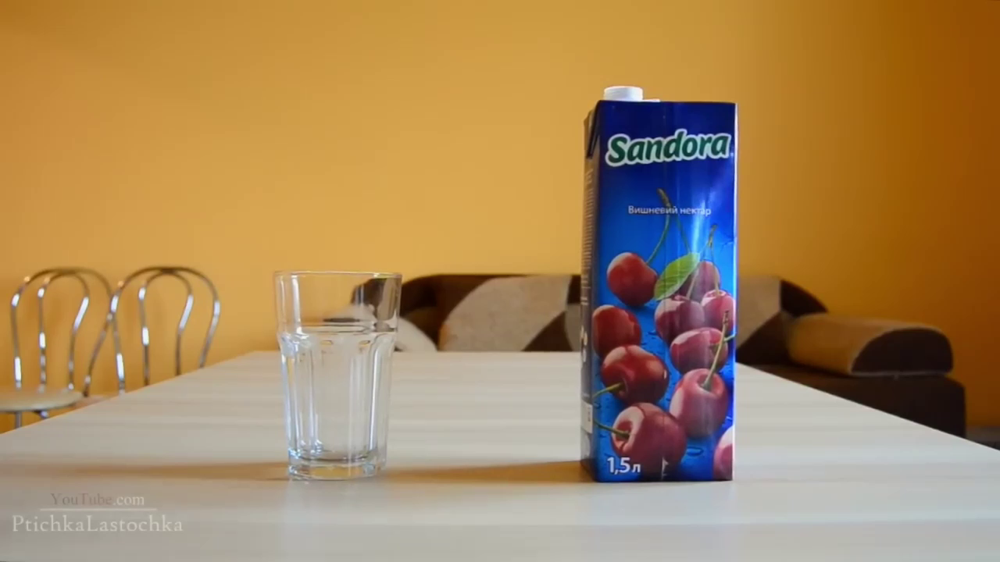

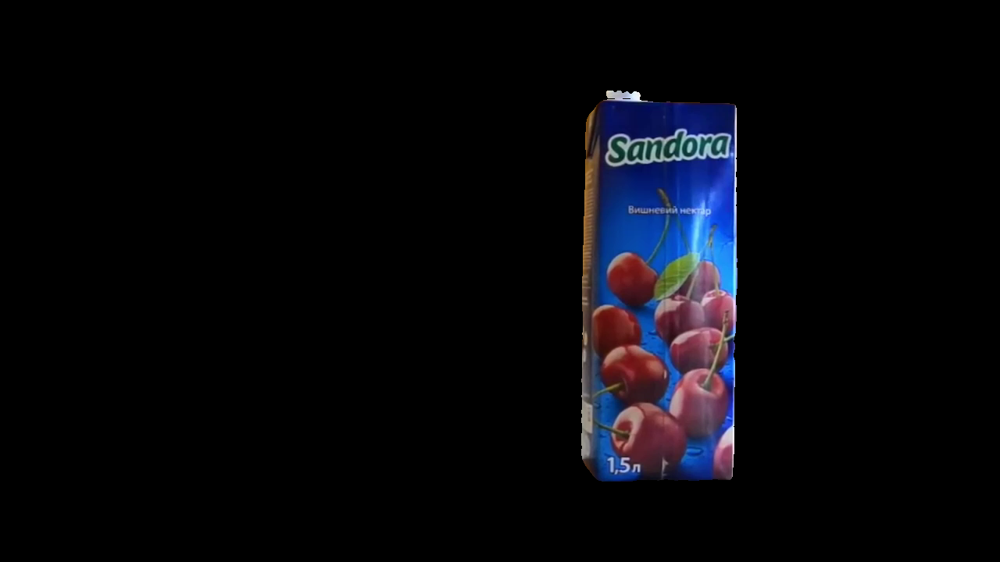

[372 748]


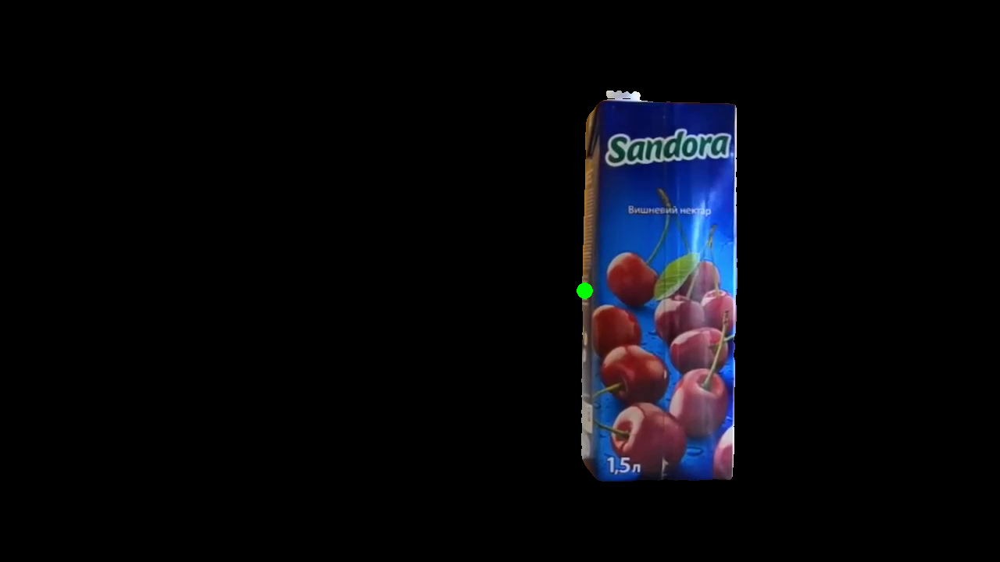

In [5]:
display(Image.fromarray(images[0]))
tgt_ob_idx = 1
masked = images[0].copy()
masked[masks_orig[0] != tgt_ob_idx] = 0
display(Image.fromarray(masked))

#get index where masks_orig == tgt_ob_idx
mask_indices = np.argwhere(masks_orig[0] == tgt_ob_idx)
point_to_trf_2d = mask_indices[mask_indices.shape[0] // 2]
#point_to_trf_2d = np.array([0,0])[None,:]
print(point_to_trf_2d)

display(Image.fromarray(cv2.circle(masked, (point_to_trf_2d[1], point_to_trf_2d[0]), 5, (0, 255, 0), 10)))

In [6]:
# keypoints = []
# for i in range(images[0].shape[0]):
#     for j in range(images[0].shape[1]):
#             keypoints.append(np.asarray([j,i]))
# keypoints = np.asarray(keypoints)
# points_3d = create_point_clouds_from_keypoints(keypoints, depths[0], K, scaling_factor=1000)

frame_idx = 0
pcd_wrapper = O3DPointCloud()
pcd_wrapper.create_from_rgbd(images[frame_idx], depths[frame_idx], K, depth_trunc=1.6)
# pcd_wrapper.pcd = o3d.geometry.PointCloud()
# pcd_wrapper.pcd.points = o3d.utility.Vector3dVector(points_3d)
# pcd_wrapper.pcd.colors = o3d.utility.Vector3dVector(images[0].reshape(-1,3))
pcd_wrapper.max_points = 10000
pcd_wrapper.preprocess()

untransformed_points = pcd_wrapper.get_points()

plane_estimation_kwargs={
        "ransac_n": 3,
        "num_iterations": 1000,
        "distance_threshold": .005
    }

plane_estimation_result = pcd_wrapper.plane_estimation(**plane_estimation_kwargs)
a, b, c, d = plane_estimation_result["plane_model"]
normal_vector = np.array([a, b, c])

# get centroid of point cloud
pcd_centroid = np.mean(pcd_wrapper.get_points(), axis=0)

arrow = go.Cone(
    x=[pcd_centroid[0]], y=[pcd_centroid[1]], z=[pcd_centroid[2]],
    u=[normal_vector[0]], v=[normal_vector[1]], w=[normal_vector[2]],
    sizemode="absolute", sizeref=0.2,  # Adjust sizeref to control arrow size
    colorscale=[[0, 'red'], [1, 'red']],  # Color of the arrow
    showscale=False,
    name='Normal Vector'
)

inlier_cloud = plane_estimation_result["inlier_cloud"]
#inlier_cloud.paint_uniform_color([1.0, 0, 0])

#draw the plane in the figure
# Generate a grid of points for the plane surface

mid = pcd_wrapper.get_points().mean(axis=0)
coverage = 0.1
x_vals = np.linspace(mid[0] - coverage, mid[0] + coverage, 10)  # Adjust the range as needed to cover red points
y_vals = np.linspace(mid[1] - coverage, mid[1] + coverage, 10)  # Adjust the range as needed to cover red points

# x_vals = np.linspace(-1, 1, 10)  # Adjust the range as needed to cover red points
# y_vals = np.linspace(-1, 1, 10)  # Adjust the range as needed to cover red points
x_grid, y_grid = np.meshgrid(x_vals, y_vals)

# Compute corresponding z values using the plane equation: ax + by + cz + d = 0
z_grid = (-a * x_grid - b * y_grid - d) / c

# Add the plane as a surface
plane_surface = go.Surface(
    x=x_grid, y=y_grid, z=z_grid,
    colorscale='Blues',
    opacity=0.6,  # Set the opacity so that both the plane and points are visible
    name='Plane'
)

fig = plotly_draw_3d_pcd(pcd_wrapper.get_points(), pcd_wrapper.get_colors(), offline=True, additional_point_draw_lines=True, equal_axis=True, addition_points=None)
fig.add_trace(plane_surface)
fig.add_trace(arrow)

display(fig)

[[ 0.12977947 -0.20848444  1.02199996]
 [ 0.10267661 -0.14973673  0.74599999]
 [ 0.09374173 -0.14852585  0.74299997]
 ...
 [ 0.18824456  0.16852817  0.57300001]
 [ 0.21971983  0.16999875  0.57800001]
 [ 0.26322351  0.17088108  0.58099997]]
[INFO - o3d_utils.py:285] Plane equation: -0.02x + 1.00y + 0.03z + -0.18 = 0
[INFO - o3d_utils.py:290] Number of inliers: 6343


In [7]:
# If you want to view the inliers

# inlier_cloud_wrapper = O3DPointCloud()
# inlier_cloud_wrapper.pcd = inlier_cloud
# plotly_draw_3d_pcd(inlier_cloud_wrapper.get_points(), inlier_cloud_wrapper.get_colors(), offline=True, additional_point_draw_lines=True, equal_axis=True, addition_points=None)

In [ ]:
if should_align:
    T_xy_plane_align = estimate_rotation(plane_estimation_result["plane_model"], z_up=False)
    pcd_wrapper.pcd.transform(T_xy_plane_align)
else:
    T_xy_plane_align = np.identity(4)

np.save(os.path.join(annotation_folder, 'FoundationPose', experiment_name, "T_xy_plane_align.npy"), T_xy_plane_align)
print(f"Saved T_xy_plane_align.npy to {os.path.join(annotation_folder, 'FoundationPose', experiment_name, 'T_xy_plane_align.npy')}")

fig = plotly_draw_3d_pcd(pcd_wrapper.get_points(), pcd_wrapper.get_colors(), offline=True, additional_point_draw_lines=True, equal_axis=True, addition_points=None)
display(fig)


[DEBUG - o3d_utils.py:402] 1.596855236595527


FileNotFoundError: [Errno 2] No such file or directory: '/home/arisrei/research/RPL/ORION/annotations/human_demo/pour_juice/test_symmetry_issue_est_25_pour_juice_no_depth/T_xy_plane_align.npy'

In [ ]:
point_to_trf_2d = np.array([point_to_trf_2d[1], point_to_trf_2d[0]])[None,:]
print(point_to_trf_2d.shape)


(1, 2)


In [ ]:
traj_3d = []
point_to_trf = np.array([0,0,0,1])
for i in range(0, all_center_poses.shape[0], 1):
    curr_pose = all_center_poses[i]
    transformed = curr_pose @ point_to_trf
    traj_3d.append(transformed[:3])

traj_3d = np.asarray(traj_3d)
traj_3d = transform_points(T_xy_plane_align, traj_3d)
traj_3d = [np.asarray(traj_3d)]

In [ ]:
#IF NO DEPTH
axes_pt_seq, traces = draw_pose_axes(all_center_poses, point_to_trf)

fig = plotly_draw_3d_pcd(offline=True, additional_point_draw_lines=True, equal_axis=True, addition_points=traj_3d)

# for trace in traces:
#     fig.add_traces(trace)

display(fig)

In [ ]:
centroid_traj = []
plane_aligned_poses = np.zeros_like(all_poses)
mesh_centroid = mesh.centroid[None, :]
print(mesh_centroid)
print(to_homo(mesh_centroid))
mesh_centroid = to_homo(mesh_centroid)

print((all_poses[0] @ mesh_centroid.T).T[0])

for i in range(0, all_poses.shape[0], sample_every):
    pose = all_poses[i]
    plane_aligned_poses[i] = T_xy_plane_align @ pose
    new_coord = (pose @ mesh_centroid.T).T[0, :3]
    centroid_traj.append(new_coord)

centroid_traj = np.array(centroid_traj)
print(centroid_traj[0:2])
print(traj_3d[0][0:2])
print('===========')
if 'depths' in locals():
    centroid_traj = transform_points(T_xy_plane_align, centroid_traj)

centroid_traj = [np.array(centroid_traj)]
print(centroid_traj[0][0:2])
print(traj_3d[0][0:2])



    
    

[[ 0.00031742 -0.00032905 -0.00027178]]
[[ 3.17420659e-04 -3.29048262e-04 -2.71781383e-04  1.00000000e+00]]
[0.10756834 0.00618863 0.65555483 1.        ]
[[0.10756834 0.00618863 0.65555483]
 [0.10834368 0.0063913  0.65475508]]
[[ 0.09595248  0.65747173 -0.02121832]
 [ 0.          0.          0.        ]]
[[ 0.09564405  0.65709792 -0.02087868]
 [ 0.09643758  0.65630804 -0.02104672]]
[[ 0.09595248  0.65747173 -0.02121832]
 [ 0.          0.          0.        ]]


In [ ]:
# centroid_traj_2 = []
# all_poses_2 = np.load("/home/arisrei/research/RPL/ORION/annotations/human_demo/long_horizon_rearrangement_cheese_4_demo/FoundationPose/cheese_block_instantmesh_from_video_gt_scaling_100_long_horizon_rearrangement_cheese_4_demo_no_depth/all_poses.npy")

# for i in range(0, all_poses_2.shape[0], sample_every):
#     pose = all_poses_2[i]
#     new_coord = (pose @ mesh_centroid.T).T[0, :3]
#     centroid_traj_2.append(new_coord)

# centroid_traj_2 = np.array(centroid_traj_2)
# if 'depths' in locals():
#     centroid_traj_2 = transform_points(T_xy_plane_align, centroid_traj_2)

# centroid_traj_2 = [np.array(centroid_traj_2)]
# centroid_traj.append(centroid_traj_2[0])

In [ ]:
# import numpy as np

# import matplotlib.pyplot as plt

# distances = np.linalg.norm(centroid_traj[0] - centroid_traj[1], axis=1)
# plt.plot(distances)
# plt.xlabel('Point Index')
# plt.ylabel('Euclidean Distance')
# plt.title('Euclidean Distance between Trajectory Points')
# plt.show()

In [ ]:
axes_pt_seq, traces = draw_pose_axes(all_poses, mesh_centroid[0], T_xy_plane_align, sample_every=sample_every)

fig = plotly_draw_3d_pcd(pcd_wrapper.get_points(), pcd_wrapper.get_colors(), offline=True, additional_point_draw_lines=True, equal_axis=True, addition_points=centroid_traj)

# for trace in traces:
#     fig.add_traces(trace)
print(centroid_traj[0][0])
display(fig)

[ 0.09564405  0.65709792 -0.02087868]


In [ ]:
np.save(os.path.join(foundation_pose_dir, experiment_name, "plane_aligned_poses.npy"), plane_aligned_poses)

In [ ]:
viz_folder = os.path.join("../../visualization", demo_name)
os.makedirs(viz_folder, exist_ok=True)
fig.write_html(os.path.join(viz_folder, f"pose_and_traj_{experiment_name}.html"))
print('saved to ', os.path.abspath(os.path.join(viz_folder, f"pose_and_traj_{experiment_name}.html")))

for trace in traces:
    fig.add_traces(trace)
fig.write_html(os.path.join(viz_folder, f"pose_and_traj_{experiment_name}_traces.html"))
print('saved to ', os.path.abspath(os.path.join(viz_folder, f"pose_and_traj_{experiment_name}_traces.html")))


saved to  /home/arisrei/research/RPL/ORION/visualization/pour_juice/pose_and_traj_test_symmetry_issue_est_25_pour_juice_no_depth.html
saved to  /home/arisrei/research/RPL/ORION/visualization/pour_juice/pose_and_traj_test_symmetry_issue_est_25_pour_juice_no_depth_traces.html


In [ ]:
# pcd_wrapper_2 = O3DPointCloud()
# pcd_wrapper_2.create_from_rgbd(images[-1], depths[-1], K)
# pcd_wrapper_2.max_points = 80000
# pcd_wrapper_2.preprocess()

# plane_estimation_result = pcd_wrapper_2.plane_estimation(**plane_estimation_kwargs)
# if should_align:
#     T_xy_plane_align = estimate_rotation(plane_estimation_result["plane_model"])
#     pcd_wrapper_2.pcd.transform(T_xy_plane_align)

# plotly_draw_3d_pcd(pcd_wrapper_2.get_points(), pcd_wrapper_2.get_colors(), offline=False, additional_point_draw_lines=True, equal_axis=True, addition_points=traj_3d)

In [ ]:
# pcd_wrapper_2.save(os.path.join("/home/arisrei/research/RPL/ORION/junk", "pcd_wrapper_2.ply"))